# igraph Tutorial

From https://igraph.org/python/doc/tutorial/tutorial.html

In [1]:
# Import igraph
from igraph import *

## Creating a graph from scratch

In [2]:
g = Graph()
# undirected graph with no vertices or edges

g

In [3]:
print(g)

# four-character code
# number of vertices (0)
# number of edges (0)
# two dashes
# name of graph ("")

IGRAPH U--- 0 0 --


In [4]:
# add 3 vertices to graph g
g.add_vertices(3)

print(g)

IGRAPH U--- 3 0 --


In [5]:
# igraph uses integer vertex IDs starting from zero,
# thus the first vertex of your graph has index zero, 
# the second vertex has index 1 and so on.

# add two specific edges
g.add_edges([(0,1),(1,2)])

print(g)

IGRAPH U--- 3 2 --
+ edges:
0--1 1--2


In [6]:
# adding more vertices and edges 
g.add_edges([(2,0)])
g.add_vertices(3)
g.add_edges([(2,3),(3,4),(4,5),(5,3)])
print(g)

IGRAPH U--- 6 7 --
+ edges:
0--1 1--2 0--2 2--3 3--4 4--5 3--5


In [7]:
g.get_eid(2,3)

3

In [8]:
g.delete_edges(3)
summary(g)
# use summary instead of print when dealing with large graphs

IGRAPH U--- 6 6 -- 


In [9]:
print(g)

IGRAPH U--- 6 6 --
+ edges:
0--1 1--2 0--2 3--4 4--5 3--5


## Generating graphs

In [10]:
# Regular tree graph, 127 vertices, each vertex with two children

g = Graph.Tree(127,2)
summary(g)

IGRAPH U--- 127 126 -- 


In [11]:
# Tree graph is deterministic
g2 = Graph.Tree(127,2)
g2.get_edgelist() == g.get_edgelist()

True

In [12]:
g2.get_edgelist()[0:10]

[(0, 1),
 (0, 2),
 (1, 3),
 (1, 4),
 (2, 5),
 (2, 6),
 (3, 7),
 (3, 8),
 (4, 9),
 (4, 10)]

In [13]:
# Stochastic graph generator
# Geometric random graph:
# n=100 points chosen randomly and uniformly inside unit square
# pairs of points closer to each other than predefined distance d=0.2
# are connected by edges

g = Graph.GRG(100,0.2)
summary(g)

IGRAPH U--- 100 522 -- 
+ attr: x (v), y (v)


In [14]:
g2 = Graph.GRG(100,0.2)
g2.get_edgelist() == g.get_edgelist()

False

In [15]:
# Check if graph g is isomorphic with g2
g.isomorphic(g2)

False

## Setting and retrieving attributes

In [16]:
# attributes: auxiliary objects associated with given graph, vertex or edge
# every graph, vertex and edge behaves as standard Python dictionary
# Can add key-value pairs to any of them
# key = name of attribute; value = attribute itself

# Warning: saving graphs to a fire only saves string and numeric attributes

# Simple imaginary social network by hand
g = Graph([(0,1), (0,2), (2,3), (3,4), (4,2), 
           (2,5), (5,0), (6,3), (5,6)])

In [17]:
summary(g)

IGRAPH U--- 7 9 -- 


In [18]:
# Every Graph object contains two special members called vs and es,
# vs = sequence of all vertices
# es = sequence of all edges

g.vs

In [19]:
g.vs["name"] = ["Alice", "Bob", "Claire", "Dennis", 
                "Esther", "Frank", "George"]
g.vs["age"] = [25, 31, 18, 47, 
               22, 23, 50]
g.vs["gender"] = ["f", "m", "f", "m", 
                  "f", "m", "m"]
g.es["is_formal"] = [False, False, True, True, True, 
                     False, True, False, False]

In [20]:
# Attributes of individual vertices/edges can be altered by indexing 
# to create a single Vertex or Edge object

# Vertex and Edge objects can also be used as dictionaries to alter the 
# attributes of that single vertex or edge
g.es[0]

igraph.Edge(<igraph.Graph object at 0x1125b15e0>, 0, {'is_formal': False})

In [21]:
g.es[0].attributes()

{'is_formal': False}

In [22]:
g.es[0]["is_formal"] = True
g.es[0]

igraph.Edge(<igraph.Graph object at 0x1125b15e0>, 0, {'is_formal': True})

In [23]:
# Other potential edge object attributes:
# source = source vertex of edge
# target = target vertex of edge
# index = edge ID
# tuple = tuple containing the source and target vertices
# attributes() = dictionary of all attributes of edge
g.es[0].source

0

In [24]:
g.es[0].target

1

In [25]:
# Attributes can also be assigned to a whole graph

g["date"] = "2009-01-10"
print(g["date"])

2009-01-10


In [26]:
# Attributes can be deleted by "del"
g.vs[3]["foo"] = "bar"
g.vs["foo"]

[None, None, None, 'bar', None, None, None]

In [27]:
del g.vs["foo"]
# g.vs["foo"] should give error

## Structural properties of graphs

In [28]:
# vertex degree
# for directed graphs:
# in-degree: g.degree(mode="in")
# out-degree: g.degree(mode="out")
g.degree()

[3, 1, 4, 3, 2, 3, 2]

In [29]:
# degree for subset of vertices
g.degree(6)

2

In [30]:
g.degree([2,3,4])

[4, 3, 2]

In [31]:
# Edge betweenness
g.edge_betweenness()

[6.0, 6.0, 4.0, 2.0, 4.0, 3.0, 4.0, 3.0, 4.0]

In [32]:
# find which connections have highest betweenness centrality
ebs = g.edge_betweenness()
max_eb = max(ebs)
print(max_eb)

6.0


In [33]:
# enumerate = get numeric indices of ebs
# Get tuple of edge sequences in graph g, for which
# index of edge  = index of ebs corresponding to max_eb
[g.es[idx].tuple for idx, eb in enumerate(ebs) if eb == max_eb]

[(0, 1), (0, 2)]

In [34]:
# Most structural properties can be retrieved for subset of edges/vertices
g.vs.degree()

[3, 1, 4, 3, 2, 3, 2]

In [35]:
g.es.edge_betweenness()

[6.0, 6.0, 4.0, 2.0, 4.0, 3.0, 4.0, 3.0, 4.0]

In [36]:
g.vs[2].degree()

4

## Querying vertices and edges based on attributes

### Selecting vertices and edges

In [37]:
# Get names of those vertices/nodes/individuals with highest degree
# .select() = method of VertexSeq; filter vertex sequence based on
# properties of vertices
# _degree = positional arguments, no explicit name
# positional arguments are processed before keyword arguments
g.vs.select(_degree = g.maxdegree())["name"]

['Claire']

In [38]:
# For some reason this is different from the answer given in tutorial
# But Claire is the right answer...

If the first positional argument is none, returns empty sequence

In [39]:
seq = g.vs.select(None)
len(seq)

0

If the first positional argument is a callable object 
(e.g. function, bound method), object will be called for every vertex
currently in sequence

If function returns True, vertex will be included

In [40]:
# Create a full graph with 10 vertices
graph = Graph.Full(10)
only_odd_vertices = graph.vs.select(lambda vertex: vertex.index % 2 == 1)
len(only_odd_vertices)

5

If the first positional argument is an iterable 
(i.e., list, generator or anything that can be iterated over),
it must return integer indices of the current vertex set
(which is not necessarily the whole graph).

In [41]:
seq = graph.vs.select([2,3,7])
len(seq)

3

In [42]:
[v.index for v in seq]

[2, 3, 7]

In [43]:
# filtering an existing vertex set
seq = seq.select([0,2])
[v.index for v in seq]

[2, 7]

In [44]:
# seq = g.vs.select([2, 3, 7, "foo", 3.5])
# igraph seems to no longer ignore floats, strings or invalid vertexID,
# and instead spits an error ("vertex index out of range").
# len(seq)

If the first positional argument is an integer, all remaining arguments are also expected to be integers and they are interpreted as indices into the current vertex set. 

This is just syntactic sugar, you could achieve an equivalent effect by passing a list as the first positional argument, but this way you can omit the square brackets

In [45]:
seq = graph.vs.select(2,3,7)
len(seq)

3

Keyword arguments can be used to filter the vertices based on their attributes or their structural properties. The name of each keyword argument should consist of at most two parts: the name of the attribute or structural property and the filtering operator. The operator can be omitted; in that case, we automatically assume the equality operator. The possibilities are as follows (where name denotes the name of the attribute or property):

- name_eq = equal 
- name_ne = not equal
- name_lt = less than
- name_le = less than or equal
- name_gt = greater than
- name_ge = greater than or equal
- name_in = included in
- name_notin = not included in

In [46]:
# people younger than 30 in network
g.vs.select(age_lt=30)

In [47]:
# same command by omitting "select"
g.vs(age_lt=30)

There can be situations where attribute and structural property
have same name (e.g. vertex attribute named degree)

THerefore, structural property must always be preceded by underscore

In [48]:
# Find vertices with degree > 2
g.vs(_degree_gt = 2)

Use _source or _from to filter edges based on source vertex

In [49]:
# getting all edges originating from source node 2 (= Claire)
g.es.select(_source=2)

Likewise, use _target or _to to filter based on target vertex

In [50]:
g.es.select(_target=2)

Use _within to take a EdgeSeq and select all edges that 
originate and terminate in given VertexSeq

In [51]:
# Select edges betwen vertices 2, 3 and 4: Claire, Dennis and Esther
g.es.select(_within=[2,3,4])

In [52]:
# Using an actual VertexSeq object
g.es.select(_within=g.vs[2:4])

Use _between to take a tuple of two VertexSeq objects 
or lists with vertex indices, or Vertex objects,
and selects all edges that originate in one set and terminate in other

In [53]:
# E.g. select all edges connecting men to women
men = g.vs.select(gender="m")
women = g.vs.select(gender="f")
g.es.select(_between=(men, women))

### Finding a single vertex or edge with some properties

In [54]:
claire = g.vs.find(name="Claire")
type(claire)

igraph.Vertex

In [55]:
claire.index

2

In [56]:
# Looking up an unknown name will yield exception
# g.vs.find(name="Joe")

### Looking up vertices by names

In [57]:
g.degree("Dennis")

3

In [58]:
g.vs.find("Dennis").degree()

3

However, uniqueness of vertex names is not enforced; you can easily create a graph where two vertices have the same name, but igraph will return only one of them when you look them up by names, the other one will be available only by its index.

# Layouts and plotting
(needs Cairo library)

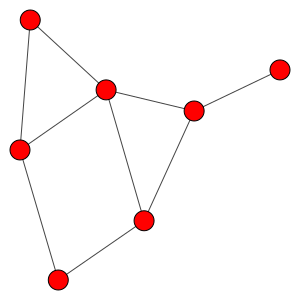

In [60]:
layout = g.layout("kk")
plot(g, layout = layout, bbox = (300, 300))

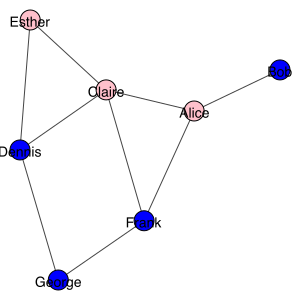

In [61]:
# Vertex labels are taken from label attribute by default
g.vs["label"] = g.vs["name"]
# Vertex colors are determined by color attribute
color_dict = {"m": "blue", "f": "pink"}
g.vs["color"] = [color_dict[gender] for gender in g.vs["gender"]]
plot(g, layout = layout, bbox = (300, 300), margin = 20)

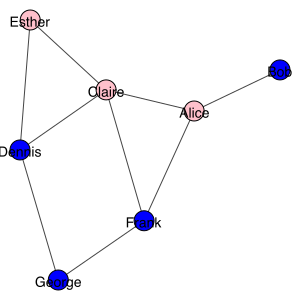

In [64]:
# Alternatively: This approach is preferred if you want to keep properties 
# of visual representation of graph separate from graph itself.
plot(g, layout = layout, 
     vertex_color = [color_dict[gender] 
                     for gender in g.vs["gender"]],
     bbox = (300, 300), margin = 20)

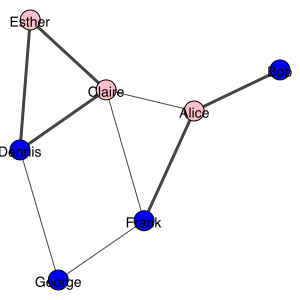

In [65]:
# Alternatively: setup a Python dictionary with keyword arguments, 
# then use double asterix operator to pass 
# specific styling attributes to plot()
visual_style = {}
visual_style["vertex_size"] = 20
visual_style["vertex_color"] = [color_dict[gender] 
                                for gender in g.vs["gender"]]
visual_style["vertex_label"] = g.vs["name"]
visual_style["edge_width"] = [1 + 2 * int(is_formal) 
                              for is_formal in g.es["is_formal"]]
visual_style["layout"] = layout
visual_style["bbox"] = (300, 300)
visual_style["margin"] = 20
plot(g, **visual_style)